# Two-pion test I: reconstruct an exact Euclidean correlator

Start with the supplied two-pion R ratio, integrate its Euclidean correlator,
and use HLT to predict $C(5)$ using **only $C(1),C(2),C(3),C(4)$**.
Scan the regularization parameter $\lambda$, inspect the reconstructed
kernel, and compute the signed bias and a model-based systematic envelope.

Run the cells from top to bottom. This notebook is self-contained;
installation and execution instructions are in [README.md](README.md).
The companion [Gaussian-noise notebook](02_two_pion_gaussian_noise.ipynb)
adds statistical errors using the same basis, target, and lambda scan.

“Exact” means no simulated measurement noise: forward transforms are still
numerical quadratures. The reconstruction uses 50 decimal digits; the last
section checks it at 70 digits. Smooth display curves use binary64 quadrature.

In [1]:
from dataclasses import replace
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

# Use this checkout whether Jupyter starts in the root or in notebooks/.
ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "src" / "spectral" / "__init__.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Start Jupyter in the spectRAL checkout or notebooks/.")
sys.path.insert(0, str(ROOT / "src"))

import spectral as sp  # noqa: E402 -- import after locating this checkout
from spectral.algorithms import hlt  # noqa: E402

%matplotlib inline
plt.rcParams.update({
    "figure.figsize": (10, 4),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})


def show_table(headers, rows):
    '''Small notebook table without an additional pandas dependency.'''
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]
    lines.extend("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown("\n".join(lines)))

## 1. Two-pion model and Euclidean correlator

The supplied `TwoPionModel` is a rho-dominance **toy model for the two-pion
contribution**, not the complete experimental hadronic R ratio. Above threshold,

$$
R_{\pi\pi}(s)=\frac14\beta_\pi(s)^3 |F_\pi(s)|^2,\qquad
\beta_\pi(s)=\sqrt{1-\frac{4m_\pi^2}{s}},
$$
$$
|F_\pi(s)|^2=
\frac{m_\rho^4}{(m_\rho^2-s)^2+s\Gamma(s)^2},\qquad
\Gamma(s)=\Gamma_\rho\frac{m_\rho}{\sqrt{s}}
\left[\frac{\beta_\pi(s)}{\beta_\pi(m_\rho^2)}\right]^3.
$$

It is zero for $\sqrt{s}\leq 2m_\pi$. The parameters are
$m_\pi=0.13957039$, $m_\rho=0.77526$, and $\Gamma_\rho=0.1491$, all in GeV.
We use the infinite-time exponential kernel (no periodic backward term):

$$
C(t)=\int_{2m_\pi}^{\infty}
\frac{\omega^2 R_{\pi\pi}(\omega^2)}{12\pi^2}e^{-\omega t}\,d\omega.
$$

Energies are in GeV, times in $\mathrm{GeV}^{-1}$, and $C$ in
$\mathrm{GeV}^3$. With the library's choice $p=2$,
$\rho_2(\omega)=R_{\pi\pi}(\omega^2)/(12\pi^2)$ and
$\phi_t(\omega)=\omega^2e^{-\omega t}$, so $C(t)=\int\rho_2\phi_t$.
The plot's energy range does **not** truncate the correlator integrals.

In [2]:
INPUT_TIMES = (1, 2, 3, 4)  # GeV^{-1}
TARGET_TIME = 5             # GeV^{-1}; deliberately absent from the input
LAMBDAS = (
    "0", "1e-10", "1e-8", "1e-6", "1e-5",
    "1e-4", "3e-4", "1e-3", "1e-2", "1e-1",
)
NUMERICS = sp.numerics.mpmath(dps=50)
PLOT_NUMERICS = sp.numerics.numpy(epsabs=1e-14, epsrel=1e-12)

model = sp.models.TwoPionModel()
basis = sp.Basis(
    kernel=sp.kernels.exponential(energy_unit="GeV"),
    times=INPUT_TIMES,
    p=2,
    omega_0=model.domain[0],
)
target = sp.targets.correlator(basis=basis)
assert TARGET_TIME not in INPUT_TIMES, "The test must withhold its target time."

In [3]:
def forward_correlator(times, *, numerics=NUMERICS):
    '''Direct model integral, with the tail integrated to infinity.'''
    with numerics.context() as ctx:
        # The physical density integrates against the ordinary exponential kernel.
        return ctx.array([
            model.integrate(basis.kernel.at_time(t), numerics=numerics)
            for t in times
        ])


C_input = forward_correlator(INPUT_TIMES)
C_truth = forward_correlator([TARGET_TIME])[0]  # Validation only; never input to HLT.
C_truth_float = float(C_truth)
print(f"Withheld reference C({TARGET_TIME}) = {C_truth_float:.12e} GeV^3")

Withheld reference C(5) = 1.228805249955e-04 GeV^3


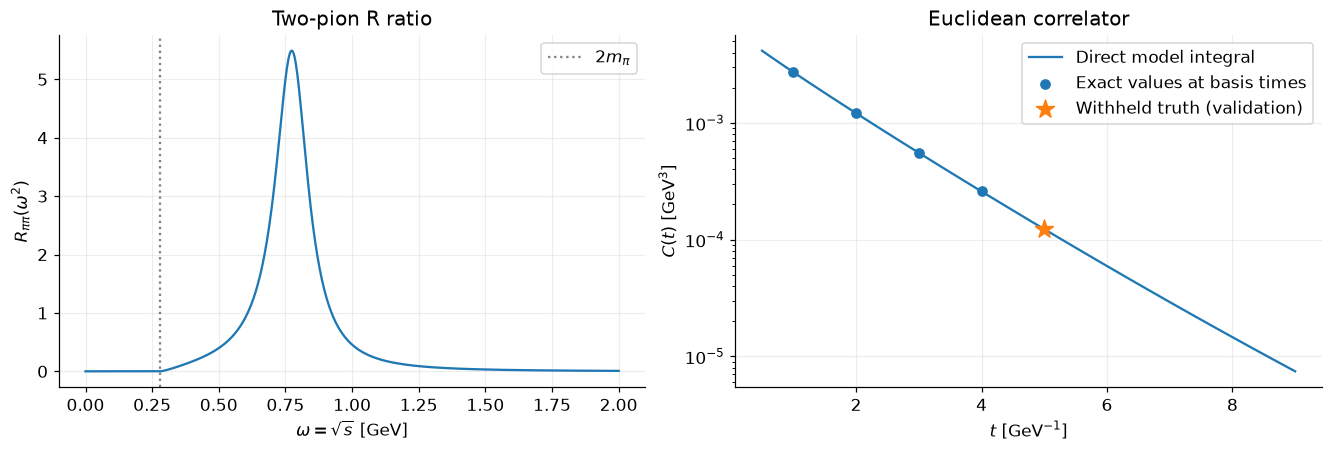

In [4]:
omega_plot = np.linspace(0, 2.0, 700)
R_plot = np.array([model.R(w**2, numerics=PLOT_NUMERICS) for w in omega_plot])
t_plot = np.linspace(0.5, 9, 120)
C_plot = np.asarray(forward_correlator(t_plot, numerics=PLOT_NUMERICS), dtype=float)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].plot(omega_plot, R_plot, color="tab:blue")
axes[0].axvline(float(model.domain[0]), color="0.5", ls=":", label=r"$2m_\pi$")
axes[0].set(xlabel=r"$\omega=\sqrt{s}$ [GeV]", ylabel=r"$R_{\pi\pi}(\omega^2)$",
            title="Two-pion R ratio")
axes[0].legend()
axes[1].semilogy(t_plot, C_plot, label="Direct model integral", color="tab:blue")
axes[1].scatter(INPUT_TIMES, np.asarray(C_input, float), color="tab:blue",
                zorder=3, label="Exact values at basis times")
axes[1].scatter([TARGET_TIME], [C_truth_float], marker="*", s=150,
                color="tab:orange", zorder=4, label="Withheld truth (validation)")
axes[1].set(xlabel=r"$t$ [GeV$^{-1}$]", ylabel=r"$C(t)$ [GeV$^3$]",
            title="Euclidean correlator")
axes[1].legend()
plt.show()

## 2. Reconstruct a time outside the basis

HLT finds coefficients $q_i(\lambda)$ whose kernel
$\widehat\phi_\lambda(\omega)=\sum_iq_i(\lambda)\phi_{t_i}(\omega)$
approximates $\phi_{t_*}$ at $t_*=5$. The estimator is then

$$\widehat C_\lambda(t_*)=\sum_i q_i(\lambda)C(t_i).$$

For these examples we use **identity regularization** in both notebooks,
with no additional constraints. This keeps the coefficients the same when
we add measurement noise. In the fixed GeV convention the minimized objective is

$$
(1-\lambda)\int_{\omega_0}^{\infty}
(\widehat\phi_\lambda-\phi_{t_*})^2\,d\omega+\lambda q^Tq,
\qquad 0\leq\lambda<1.
$$

Writing $A_{ij}=\int\phi_i\phi_j\,d\omega$ and
$b_i=\int\phi_i\phi_{t_*}\,d\omega$, the solve is
$[(1-\lambda)A+\lambda I]q=(1-\lambda)b$.
The numerical meaning of $\lambda$ depends on the units and regulator.
Increasing it suppresses the coefficient norm and changes the kernel mismatch;
it need not improve the model bias monotonically.

Here $t_*$ lies beyond the largest input time: this is an **extrapolation**.
Even at $\lambda=0$, its kernel generally cannot be represented exactly by
four basis functions. Recovering an input time at $\lambda=0$ would be a different,
easier test. The model parameters and $C(t_*)$ do not enter this solve, apart
from the chosen spectral threshold.

In [5]:
# Zero covariance describes noiseless synthetic input.
data = sp.CorrelatorData.from_arrays(
    times=INPUT_TIMES, mean=C_input, energy_unit="GeV",
)
assert np.all(np.asarray(data.covariance, float) == 0)

In [6]:
solver = hlt.Solver(lambda_=LAMBDAS, regulator="identity")
reconstructor = sp.Reconstructor(basis=basis, algorithm=solver, numerics=NUMERICS)
prediction = reconstructor.reconstruct(
    data, target=target, target_times=[TARGET_TIME],
)
# Remove the singleton target-time axis, retaining the lambda axis.
scan = prediction.at_time(TARGET_TIME)
assert tuple(scan.axes) == ("lambda",)
assert all(TARGET_TIME not in result.input_times for result in scan.results)

one = scan.at_lambda("1e-6")
with NUMERICS.context() as ctx:
    explicit_value = ctx.dot(ctx.array(one.coefficients), ctx.array(data.mean))
    assert abs(explicit_value - ctx.number(one.value)) < ctx.number("1e-40")
print("Example lambda:", one.coordinates["lambda"])
print("Input times:   ", one.input_times)
print("Coefficients:  ", np.asarray(one.coefficients, dtype=float))
print(f"q @ C = {float(explicit_value):.12e} GeV^3")

Example lambda: 1e-6
Input times:    (1, 2, 3, 4)
Coefficients:   [-5.29276169e-04  3.07414408e-02 -3.30987569e-01  1.06690627e+00]
q @ C = 1.283554191151e-04 GeV^3


The following plots compare the target kernel with several HLT approximations.
A small mismatch near the resonance matters strongly for this model, because
that is where the R ratio is largest. The full bias requires integrating
the signed mismatch against the spectral model.

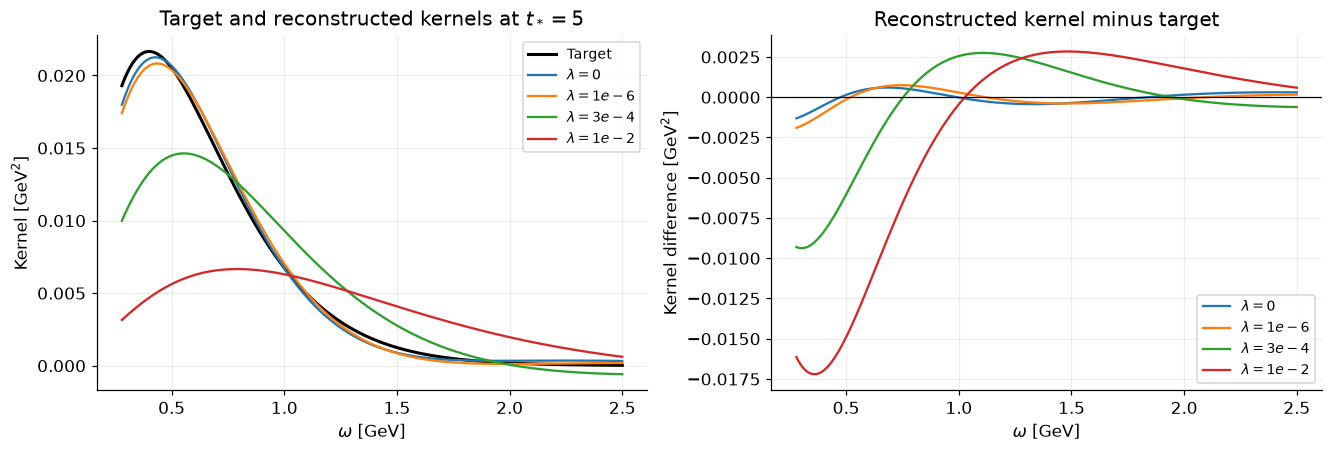

In [7]:
kernel_energies = np.linspace(float(model.domain[0]), 2.5, 300)
exact_kernel = np.asarray(basis.at_time(TARGET_TIME)(kernel_energies), float)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].plot(kernel_energies, exact_kernel, color="black", lw=2, label="Target")
for lam in ("0", "1e-6", "3e-4", "1e-2"):
    result = scan.at_lambda(lam)
    approx = np.asarray(result.approximated_kernel(kernel_energies), float)
    axes[0].plot(kernel_energies, approx, label=fr"$\lambda={lam}$")
    axes[1].plot(kernel_energies, approx - exact_kernel, label=fr"$\lambda={lam}$")
axes[0].set(xlabel=r"$\omega$ [GeV]", ylabel=r"Kernel [GeV$^2$]",
            title=fr"Target and reconstructed kernels at $t_*={TARGET_TIME}$")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(xlabel=r"$\omega$ [GeV]", ylabel=r"Kernel difference [GeV$^2$]",
            title="Reconstructed kernel minus target")
axes[0].legend(fontsize=9)
axes[1].legend(fontsize=9)
plt.show()

## 3. Signed bias and systematic uncertainty

For a spectral model $m$, compute the **signed** reconstruction bias

$$
b_\lambda^{(m)}=
\int_{\omega_0}^{\infty}
[\widehat\phi_\lambda(\omega)-\phi_{t_*}(\omega)]
\rho_2^{(m)}(\omega)\,d\omega.
$$

In the noiseless nominal model this must equal
$\widehat C_\lambda-C_{\rm truth}$. In repeated noisy experiments it is the
**expected** error, not the residual of a particular noisy draw.
The unweighted squared kernel mismatch minimized by HLT is a different quantity.

We report both $|b_\lambda^{\rm nominal}|$ and
$\sigma_{\rm sys}(\lambda)=\max_m|b_\lambda^{(m)}|$.
The latter includes the nominal model and four illustrative alternatives:
$m_\rho\pm10$ MeV, or $\Gamma_\rho\pm10\%$, one parameter at a time.
These choices demonstrate a sensitivity envelope; they are not calibrated
parameter errors, a rigorous bound, or a probabilistic one-sigma interval.
Set `deformations=None` in the estimate call to use only the nominal bias.

The same model family is reused across the lambda scan and in both notebooks.
It is separate from the Gaussian noise added to the correlator.
`estimate` integrates to infinity with adaptive quadrature and leaves the
reconstructed central values unchanged.

In [8]:
model_variations = sp.systematics.DeformationSet(
    models=(
        replace(model, m_rho="0.76526"),
        replace(model, m_rho="0.78526"),
        replace(model, gamma_rho="0.13419"),
        replace(model, gamma_rho="0.16401"),
    ),
    ids=("mass_minus_10MeV", "mass_plus_10MeV", "width_minus_10pct", "width_plus_10pct"),
    metadata={"purpose": "Illustrative parameter sensitivity; not a confidence region"},
)
report = sp.systematics.estimate(
    scan,
    reference_kernel=target,
    density=model,
    deformations=model_variations,
)

# Convert only the presentation arrays to binary64.
lambda_plot = np.asarray(LAMBDAS, dtype=float)
reconstructed = np.asarray(scan.values, dtype=float)
statistical = np.asarray(scan.statistical_errors, dtype=float)
nominal_bias = np.asarray(report.nominal_bias, dtype=float)
systematic = np.asarray(report.max_abs_bias, dtype=float)
assert np.all(systematic >= np.abs(nominal_bias))

In [9]:
# Check the sign and normalization against the known withheld correlator.
with NUMERICS.context() as ctx:
    residual = ctx.array(scan.values) - ctx.number(C_truth)
    bias_identity_error = max(abs(x) for x in residual - ctx.array(report.nominal_bias))
    assert bias_identity_error < ctx.number("1e-40")
assert np.all(statistical == 0)

show_table(
    ["lambda", "Reconstructed C [GeV^3]", "Signed nominal bias [GeV^3]",
     "|Nominal bias| [GeV^3]", "Systematic envelope [GeV^3]"],
    [
        [lam, f"{value:.8e}", f"{bias:+.5e}", f"{abs(bias):.5e}", f"{sys:.5e}"]
        for lam, value, bias, sys in zip(LAMBDAS, reconstructed, nominal_bias, systematic)
    ],
)
print(f"Truth: {C_truth_float:.12e} GeV^3")
print(f"Maximum bias-identity discrepancy: {float(bias_identity_error):.2e} GeV^3")

| lambda | Reconstructed C [GeV^3] | Signed nominal bias [GeV^3] | |Nominal bias| [GeV^3] | Systematic envelope [GeV^3] |
| --- | --- | --- | --- | --- |
| 0 | 1.26740449e-04 | +3.85992e-06 | 3.85992e-06 | 4.44694e-06 |
| 1e-10 | 1.26740637e-04 | +3.86011e-06 | 3.86011e-06 | 4.44716e-06 |
| 1e-8 | 1.26759159e-04 | +3.87863e-06 | 3.87863e-06 | 4.46856e-06 |
| 1e-6 | 1.28355419e-04 | +5.47489e-06 | 5.47489e-06 | 6.31307e-06 |
| 1e-5 | 1.33627537e-04 | +1.07470e-05 | 1.07470e-05 | 1.24205e-05 |
| 1e-4 | 1.30902444e-04 | +8.02192e-06 | 8.02192e-06 | 9.47744e-06 |
| 3e-4 | 1.21440912e-04 | -1.43961e-06 | 1.43961e-06 | 2.75605e-06 |
| 1e-3 | 1.06043662e-04 | -1.68369e-05 | 1.68369e-05 | 1.84858e-05 |
| 1e-2 | 6.28627432e-05 | -6.00178e-05 | 6.00178e-05 | 6.71293e-05 |
| 1e-1 | 1.96457585e-05 | -1.03235e-04 | 1.03235e-04 | 1.15822e-04 |

Truth: 1.228805249955e-04 GeV^3
Maximum bias-identity discrepancy: 0.00e+00 GeV^3


The error bars below show the systematic envelope around the **uncorrected**
reconstructed value. They have no probability-coverage interpretation.
The second panel separates the nominal bias magnitude from the envelope.
A symmetric-log horizontal axis keeps the $\lambda=0$ point visible.

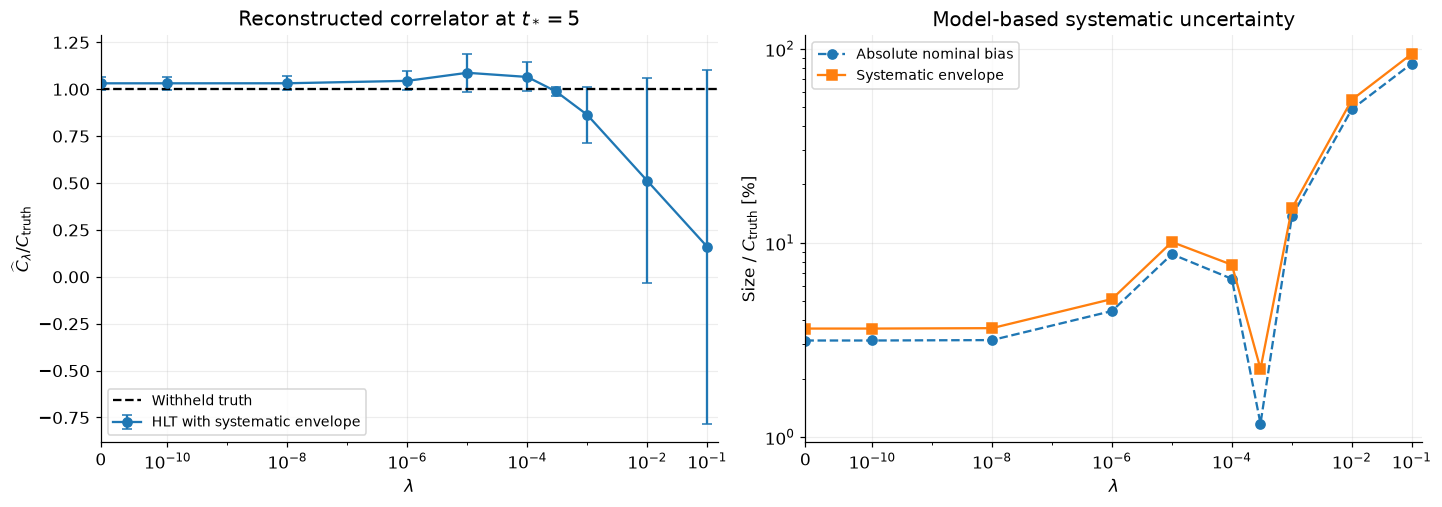

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
axes[0].errorbar(
    lambda_plot, reconstructed / C_truth_float,
    yerr=systematic / C_truth_float,
    fmt="o-", capsize=3, label="HLT with systematic envelope",
)
axes[0].axhline(1, color="black", ls="--", label="Withheld truth")
axes[0].set(xlabel=r"$\lambda$", ylabel=r"$\widehat C_\lambda/C_{\rm truth}$",
            title=fr"Reconstructed correlator at $t_*={TARGET_TIME}$")
axes[1].plot(lambda_plot, 100 * np.abs(nominal_bias) / C_truth_float,
             "o--", label="Absolute nominal bias")
axes[1].plot(lambda_plot, 100 * systematic / C_truth_float,
             "s-", label="Systematic envelope")
axes[1].set(xlabel=r"$\lambda$", ylabel=r"Size / $C_{\rm truth}$ [%]",
            yscale="log", title="Model-based systematic uncertainty")
for ax in axes:
    ax.set_xscale("symlog", linthresh=1e-10)
    ax.set_xlim(0, 0.15)
    ax.set_xticks([0, 1e-10, 1e-8, 1e-6, 1e-4, 1e-2, 1e-1])
    ax.legend(fontsize=9)
plt.show()

## 4. Numerical precision check and interpretation

Exponential bases can be ill-conditioned. Repeat the forward transform and
the HLT solve at 70 digits, using the same physical inputs and lambdas.
This checks precision sensitivity; it does not turn a finite-basis prediction
into an exact reconstruction or validate a spectral model for real data.

In [11]:
check_numerics = sp.numerics.mpmath(dps=70)
check_data = sp.CorrelatorData.from_arrays(
    times=INPUT_TIMES,
    mean=forward_correlator(INPUT_TIMES, numerics=check_numerics),
    energy_unit="GeV",
)
check_scan = sp.Reconstructor(
    basis=basis, algorithm=solver, numerics=check_numerics,
).reconstruct(check_data, target=target, target_times=[TARGET_TIME]).at_time(TARGET_TIME)
check_truth = forward_correlator([TARGET_TIME], numerics=check_numerics)[0]
with check_numerics.context() as ctx:
    differences = abs(ctx.array(scan.values) - ctx.array(check_scan.values))
    max_precision_shift = max(differences) / abs(ctx.number(check_truth))
    truth_precision_shift = abs(ctx.number(C_truth) - check_truth) / abs(check_truth)
    assert max_precision_shift < ctx.number("1e-30")
    assert truth_precision_shift < ctx.number("1e-30")
print(f"Maximum relative reconstruction shift, 50 to 70 digits: {float(max_precision_shift):.2e}")
print(f"Relative direct-correlator shift, 50 to 70 digits: {float(truth_precision_shift):.2e}")

Maximum relative reconstruction shift, 50 to 70 digits: 3.50e-50
Relative direct-correlator shift, 50 to 70 digits: 2.02e-52


With the default four-time basis, the nominal bias at $\lambda=0$ is about
**3.14%**, despite the absence of measurement noise. More regularization can
initially increase this bias and later change its sign; a small bias at
one lambda can result from cancellations against this particular spectrum.
The envelope probes a limited set of alternative spectra.

Try moving `TARGET_TIME` inside the input-time range while keeping it absent
from `INPUT_TIMES`, or enlarge the basis and repeat the precision check.
Keep $p$, the spectral model, energy units, and integration threshold consistent.
In the next notebook, the covariance introduces a separate statistical error.